# Figure 3 · Tách hai nhóm đặc trưng

**Nguồn chính** · Kết quả từng lượt do tác giả công bố. Notebook chạy lại phép phân tích và vẽ hình bằng Python. Lần mở đầu cần Internet để tải và đối chiếu SHA-256.

## Cách đọc thí nghiệm

Xếp hạng đặc trưng bằng Random Forest của tác giả. Với GBT, tách hai nhánh dùng nhóm giữ lại và chỉ dùng nhóm bị loại. Điểm được chuẩn hóa để 0,5 accuracy gốc ứng với 0. Ở hạng 20, lấy trung bình qua 30 lần xáo, sau đó lấy trung bình và phân vị 10%–90% qua các bộ dữ liệu. Nhánh dùng nhóm bị loại ở mức 0% không có điểm.

In [1]:
from pathlib import Path
import sys

root = next(folder for folder in (Path.cwd(), *Path.cwd().parents)
            if (folder / "src/analysis.py").is_file())
sys.path.insert(0, str(root))
from IPython.display import Image, display
import matplotlib.pyplot as plt
from src.analysis import analyze
from src.author_data import SOURCES, prepare
from src.plots import export, export_project

source = "ablations"
cache = prepare(source)
print("SHA-256 nguồn:", SOURCES[source].sha256)

SHA-256 nguồn: 25314ccb2d138dae43fd23840f729f62fba0b5f5ab559aeb3727403dedb4e429


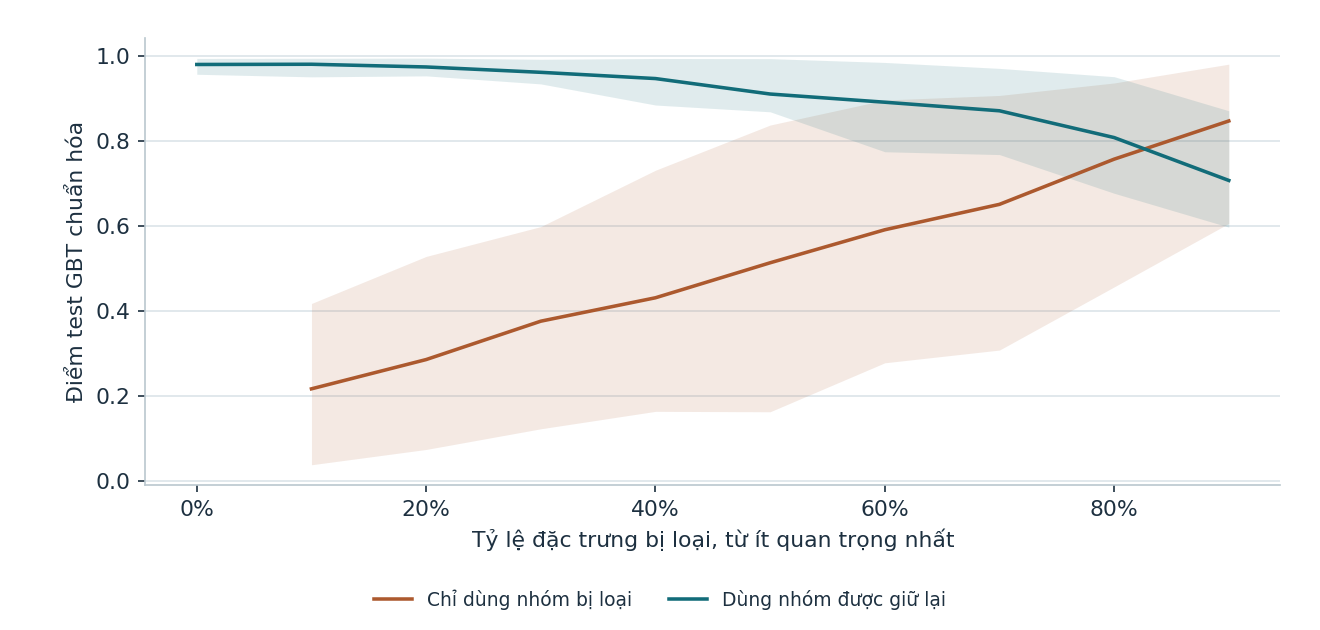

In [2]:
figure_number = 3
scores = analyze(figure_number)
chart = export(figure_number, scores)
plt.close(chart)
display(Image(filename=str(root / "figures" / f"figure_{figure_number:02d}.png")))

## Một số giá trị đứng sau biểu đồ

In [3]:
display(scores.head(8).round(5))

,transform__0__num_features_to_remove,method,mean,count,low,high
0,0.0,keep,NaN,0,NaN,NaN
1,0.0,remove,0.97983,15,0.95681,0.99409
2,0.1,keep,0.21716,11,0.03862,0.41785
3,0.1,remove,0.98037,15,0.95073,0.99442
4,0.2,keep,0.28598,15,0.07460,0.52847
5,0.2,remove,0.97399,15,0.95305,0.99476
6,0.3,keep,0.37624,15,0.12321,0.59866
7,0.3,remove,0.96140,15,0.93415,0.99209


## Quy trình train trong repo tác giả

**Minh họa quy trình, không có fit mới ở notebook này.** Điểm vào: `src/launch_benchmarks/launch_xps.py · uninformative_features`. Xếp hạng RF trên train; chọn một tỷ lệ công bố; chạy GBT trên phần giữ lại và trên phần bị loại; chấm điểm từng nhánh.

Nếu tái chạy độc lập, dùng cấu hình đầy đủ của đúng model, task và điều kiện từ CSV nguồn. Repo gốc có lệnh chuẩn bị môi trường, launcher và `train_model_on_config`; khóa phiên bản source trước khi chạy. 

### Ví dụ cấu hình đã công bố

Các giá trị dưới đây trích từ dòng đầu tiên của GBT trong từng nhánh, theo thứ tự CSV. File lịch sử dùng tên bộ dữ liệu và loader `real_data`. Launcher pin hiện tại dùng OpenML task ID và `openml_no_transform`, nên cần đối chiếu đầu vào khi chạy lại ví dụ.

In [4]:
import json
import pandas as pd
published = json.loads((root / "evidence/published_config_examples.json").read_text(encoding="utf-8"))
names = ('show_uninformative_features',)
display(pd.DataFrame({name: published["examples"][name]["settings"] for name in names}).fillna("—"))

,show_uninformative_features
data__keyword,eye_movements
data__method_name,real_data
max_test_samples,50000
max_train_samples,10000
max_val_samples,50000
model__learning_rate,2.2484712005464e-4
model__loss,deviance
model__min_samples_leaf,3
model__min_samples_split,2
model__n_estimators,42


## Nguồn

- [Paper NeurIPS 2022](https://papers.neurips.cc/paper_files/paper/2022/hash/0378c7692da36807bdec87ab043cdadc-Abstract-Datasets_and_Benchmarks.html)
- [Repo tác giả, commit đã đối chiếu](https://github.com/LeoGrin/tabular-benchmark/tree/9d54cf53d9fd3159e367e70a00005f4fcbf2c79d)
